# Execução das consultas SQL e gráficos — Northwind

Este notebook **não refaz a análise em Python**: ele lê os arquivos da pasta `sql/`,
executa cada consulta no banco SQLite e mostra o resultado. Assim, todo número do
README sai diretamente do SQL.

**Fluxo:** `data/*.csv` → `scripts/criar_banco.py` → `database/northwind.db` → consultas `sql/01` a `sql/05` → `results/Qxx.csv` + `images/*.png`

**Definição usada em todo o projeto:** receita líquida = preço praticado × quantidade × (1 − desconto), sem frete.
Valores na moeda original da base (dólar).

In [1]:
import sqlite3
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))

# Cria o banco a partir dos CSVs se ele ainda não existir
if not (RAIZ / "database" / "northwind.db").exists():
    subprocess.run([sys.executable, str(RAIZ / "scripts" / "criar_banco.py")], check=True)

from executar_consultas import carregar_consultas, executar, ARQUIVO_BANCO

con = sqlite3.connect(ARQUIVO_BANCO)
consultas = {c["id"]: c for c in carregar_consultas()}
(RAIZ / "results").mkdir(exist_ok=True)
(RAIZ / "images").mkdir(exist_ok=True)
pd.set_option("display.max_rows", 80)

def rodar(qid, mostrar=True):
    c = consultas[qid]
    df = executar(con, c)
    df.to_csv(RAIZ / "results" / f"{qid}.csv", index=False, encoding="utf-8")
    if mostrar:
        print(f"[{qid}] {c['titulo']}  ({c['arquivo']}, {len(df)} linhas)")
    return df

# Estilo dos gráficos (paleta validada para daltonismo)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#9a9893"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c7c0", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left",
})
milhar = mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f} mil".replace(",", "."))

def salvar(fig, nome):
    fig.savefig(RAIZ / "images" / nome, facecolor="white")
    plt.show()

print(f"{len(consultas)} consultas carregadas")

28 consultas carregadas


## Módulo 1 — Extração com SELECT, WHERE e ORDER BY (`sql/01_consultas_basicas.sql`)

In [2]:
rodar("Q01")

[Q01] Os 10 produtos ativos mais caros do catálogo  (01_consultas_basicas.sql, 10 linhas)


,product_id,product_name,quantity_per_unit,unit_price,units_in_stock
0,38,Côte de Blaye,12 - 75 cl bottles,263.5,17
1,20,Sir Rodney's Marmalade,30 gift boxes,81.0,40
2,18,Carnarvon Tigers,16 kg pkg.,62.5,42
3,59,Raclette Courdavault,5 kg pkg.,55.0,79
4,51,Manjimup Dried Apples,50 - 300 g pkgs.,53.0,20
5,62,Tarte au sucre,48 pies,49.3,17
6,43,Ipoh Coffee,16 - 500 g tins,46.0,17
7,27,Schoggi Schokolade,100 - 100 g pieces,43.9,49
8,63,Vegie-spread,15 - 625 g jars,43.9,24
9,8,Northwoods Cranberry Sauce,12 - 12 oz jars,40.0,6


In [3]:
rodar("Q02")

[Q02] Produtos ativos com estoque no ponto de reposição ou abaixo  (01_consultas_basicas.sql, 17 linhas)


,product_id,product_name,units_in_stock,units_on_order,reorder_level,cobertura_com_pedidos
0,30,Nord-Ost Matjeshering,10,0,15,Comprar agora
1,70,Outback Lager,15,10,30,Comprar agora
2,31,Gorgonzola Telino,0,70,20,Reposição já encomendada
3,21,Sir Rodney's Scones,3,40,5,Reposição já encomendada
4,66,Louisiana Hot Spiced Okra,4,100,20,Reposição já encomendada
5,74,Longlife Tofu,4,20,5,Reposição já encomendada
6,45,Rogede sild,5,70,15,Reposição já encomendada
7,68,Scottish Longbreads,6,10,15,Reposição já encomendada
8,32,Mascarpone Fabioli,9,40,25,Reposição já encomendada
9,49,Maxilaku,10,60,15,Reposição já encomendada


In [4]:
rodar("Q03")

[Q03] Pedidos entregues depois da data prometida ao cliente  (01_consultas_basicas.sql, 37 linhas)


,order_id,customer_id,order_date,required_date,shipped_date,dias_atraso
0,10777,GOURL,1997-12-15,1997-12-29,1998-01-21,23
1,10423,GOURL,1997-01-23,1997-02-06,1997-02-24,18
2,10726,EASTC,1997-11-03,1997-11-17,1997-12-05,18
3,10970,BOLID,1998-03-24,1998-04-07,1998-04-24,17
4,10515,QUICK,1997-04-23,1997-05-07,1997-05-23,16
5,10827,BONAP,1998-01-12,1998-01-26,1998-02-06,11
6,10660,HUNGC,1997-09-08,1997-10-06,1997-10-15,9
7,10663,BONAP,1997-09-10,1997-09-24,1997-10-03,9
8,10828,RANCH,1998-01-13,1998-01-27,1998-02-04,8
9,10380,HUNGO,1996-12-12,1997-01-09,1997-01-16,7


In [5]:
rodar("Q04")

[Q04] Pedidos ainda não enviados (sem data de envio)  (01_consultas_basicas.sql, 21 linhas)


,order_id,customer_id,order_date,required_date,dias_em_aberto
0,11008,ERNSH,1998-04-08,1998-05-06,28
1,11019,RANCH,1998-04-13,1998-05-11,23
2,11039,LINOD,1998-04-21,1998-05-19,15
3,11040,GREAL,1998-04-22,1998-05-20,14
4,11045,BOTTM,1998-04-23,1998-05-21,13
5,11051,LAMAI,1998-04-27,1998-05-25,9
6,11054,CACTU,1998-04-28,1998-05-26,8
7,11058,BLAUS,1998-04-29,1998-05-27,7
8,11059,RICAR,1998-04-29,1998-06-10,7
9,11061,GREAL,1998-04-30,1998-06-11,6


In [6]:
rodar("Q05")

[Q05] Pedidos do 1º trimestre de 1998 com frete acima de 100,  (01_consultas_basicas.sql, 19 linhas)


,order_id,customer_id,order_date,ship_country,freight
0,10816,GREAL,1998-01-06,USA,719.78
1,10983,SAVEA,1998-03-27,USA,657.54
2,10847,SAVEA,1998-01-22,USA,487.57
3,10941,SAVEA,1998-03-11,USA,400.81
4,10865,QUICK,1998-02-02,Germany,348.14
5,10817,KOEN,1998-01-06,Germany,306.07
6,10889,RATTC,1998-02-16,USA,280.61
7,10962,QUICK,1998-03-19,Germany,275.79
8,10845,QUICK,1998-01-21,Germany,212.98
9,10984,SAVEA,1998-03-30,USA,211.22


In [7]:
rodar("Q06")

[Q06] Clientes cujo nome da empresa contém "Restaurant" ou "Café"  (01_consultas_basicas.sql, 3 linhas)


,customer_id,company_name,city,country
0,TORTU,Tortuga Restaurante,México D.F.,Mexico
1,LONEP,Lonesome Pine Restaurant,Portland,USA
2,GROSR,GROSELLA-Restaurante,Caracas,Venezuela


**Leitura:** 17 produtos ativos estão no ponto de reposição ou abaixo, mas só 2
(Nord-Ost Matjeshering e Outback Lager) não têm reposição encomendada — esses são os
que pedem compra imediata. 37 pedidos foram enviados depois da data prometida e 21
ainda estavam sem envio na última data da base.

## Módulo 2 — Integração de tabelas com JOIN (`sql/02_joins.sql`)

In [8]:
rodar("Q07")

[Q07] Visão completa dos 10 pedidos mais recentes  (02_joins.sql, 10 linhas)


,order_id,order_date,cliente,pais_cliente,vendedor,transportadora,frete
0,11077,1998-05-06,Rattlesnake Canyon Grocery,USA,Nancy Davolio,United Package,8.53
1,11076,1998-05-06,Bon app',France,Margaret Peacock,United Package,38.28
2,11075,1998-05-06,Richter Supermarkt,Switzerland,Laura Callahan,United Package,6.19
3,11074,1998-05-06,Simons bistro,Denmark,Robert King,United Package,18.44
4,11073,1998-05-05,Pericles Comidas clásicas,Mexico,Andrew Fuller,United Package,24.95
5,11072,1998-05-05,Ernst Handel,Austria,Margaret Peacock,United Package,258.64
6,11071,1998-05-05,LILA-Supermercado,Venezuela,Nancy Davolio,Speedy Express,0.93
7,11070,1998-05-05,Lehmanns Marktstand,Germany,Andrew Fuller,Speedy Express,136.00
8,11069,1998-05-04,Tortuga Restaurante,Mexico,Nancy Davolio,United Package,15.67
9,11068,1998-05-04,Queen Cozinha,Brazil,Laura Callahan,United Package,81.75


In [9]:
rodar("Q08")

[Q08] Itens de pedido enriquecidos com produto, categoria e fornecedor  (02_joins.sql, 15 linhas)


,order_id,produto,categoria,fornecedor,preco_praticado,quantidade,desconto,receita_liquida
0,10981,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,60,0.00,15810.00
1,10865,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,60,0.05,15019.50
2,10417,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,210.80,50,0.00,10540.00
3,10889,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,40,0.00,10540.00
4,10897,Thüringer Rostbratwurst,Meat/Poultry,Plutzer Lebensmittelgroßmärkte AG,123.79,80,0.00,9903.20
5,10353,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,210.80,50,0.20,8432.00
6,10424,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,210.80,49,0.20,8263.36
7,10540,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,30,0.00,7905.00
8,10817,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,30,0.00,7905.00
9,10816,Côte de Blaye,Beverages,Aux joyeux ecclésiastiques,263.50,30,0.05,7509.75


In [10]:
rodar("Q09")

[Q09] Clientes cadastrados que nunca fizeram pedido  (02_joins.sql, 2 linhas)


,customer_id,company_name,city,country
0,FISSA,FISSA Fabrica Inter. Salchichas S.A.,Madrid,Spain
1,PARIS,Paris spécialités,Paris,France


In [11]:
rodar("Q10")

[Q10] Volume de pedidos por transportadora (incluindo as sem uso)  (02_joins.sql, 6 linhas)


,shipper_id,transportadora,qtd_pedidos
0,2,United Package,326
1,3,Federal Shipping,255
2,1,Speedy Express,249
3,4,Alliance Shippers,0
4,5,UPS,0
5,6,DHL,0


In [12]:
rodar("Q11")

[Q11] Hierarquia da equipe: cada funcionário e seu gestor direto  (02_joins.sql, 9 linhas)


,employee_id,funcionario,cargo,gestor_direto
0,2,Andrew Fuller,"Vice President, Sales",(topo)
1,1,Nancy Davolio,Sales Representative,Andrew Fuller
2,3,Janet Leverling,Sales Representative,Andrew Fuller
3,4,Margaret Peacock,Sales Representative,Andrew Fuller
4,5,Steven Buchanan,Sales Manager,Andrew Fuller
5,8,Laura Callahan,Inside Sales Coordinator,Andrew Fuller
6,6,Michael Suyama,Sales Representative,Steven Buchanan
7,7,Robert King,Sales Representative,Steven Buchanan
8,9,Anne Dodsworth,Sales Representative,Steven Buchanan


**Leitura:** o LEFT JOIN revela o que o INNER JOIN esconderia: 2 clientes cadastrados
nunca compraram (FISSA e Paris spécialités) e 3 transportadoras cadastradas
(Alliance Shippers, UPS e DHL) nunca foram usadas.

## Módulo 3 — Agrupamentos e agregações (`sql/03_agregacoes.sql`)

In [13]:
q12 = rodar("Q12"); q12

[Q12] Receita líquida por categoria de produto  (03_agregacoes.sql, 8 linhas)


,categoria,qtd_pedidos,unidades_vendidas,receita_liquida,desconto_medio_pct
0,Beverages,354,9532,267868.18,6.2
1,Dairy Products,303,9149,234507.29,5.3
2,Confections,295,7906,167357.23,5.7
3,Meat/Poultry,161,4199,163022.36,6.4
4,Seafood,291,7681,131261.74,6.0
5,Condiments,193,5298,106047.09,5.3
6,Produce,129,2990,99984.58,4.5
7,Grains/Cereals,182,4562,95744.59,4.5


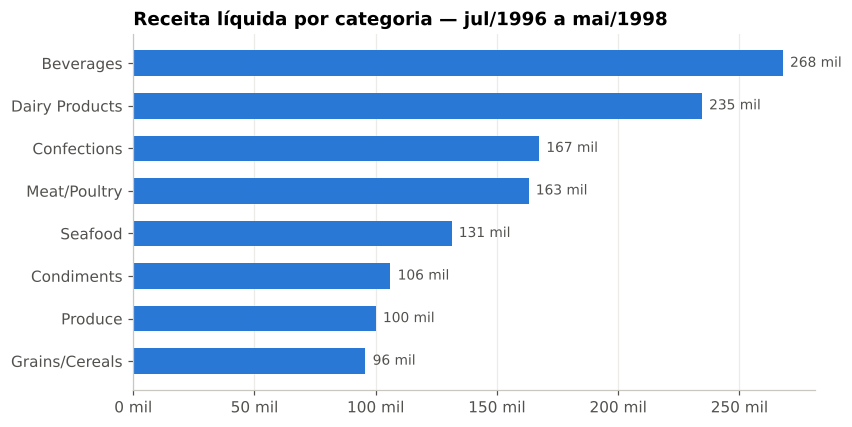

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = q12.sort_values("receita_liquida")
ax.barh(d["categoria"], d["receita_liquida"], color=AZUL, height=0.6)
for y, v in enumerate(d["receita_liquida"]):
    ax.text(v + 3000, y, f"{v/1000:,.0f} mil".replace(",", "."), va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(milhar)
ax.grid(axis="y", visible=False)
ax.set_title("Receita líquida por categoria — jul/1996 a mai/1998")
salvar(fig, "02_receita_por_categoria.png")

In [15]:
q13 = rodar("Q13"); q13

[Q13] Receita líquida por país do cliente — apenas países acima de 50 mil  (03_agregacoes.sql, 9 linhas)


,pais,clientes_ativos,qtd_pedidos,receita_liquida
0,USA,13,122,245584.61
1,Germany,11,122,230284.63
2,Austria,2,40,128003.84
3,Brazil,9,83,106925.78
4,France,10,77,81358.32
5,UK,7,56,58971.31
6,Venezuela,4,46,56810.63
7,Sweden,2,37,54495.14
8,Canada,3,30,50196.29


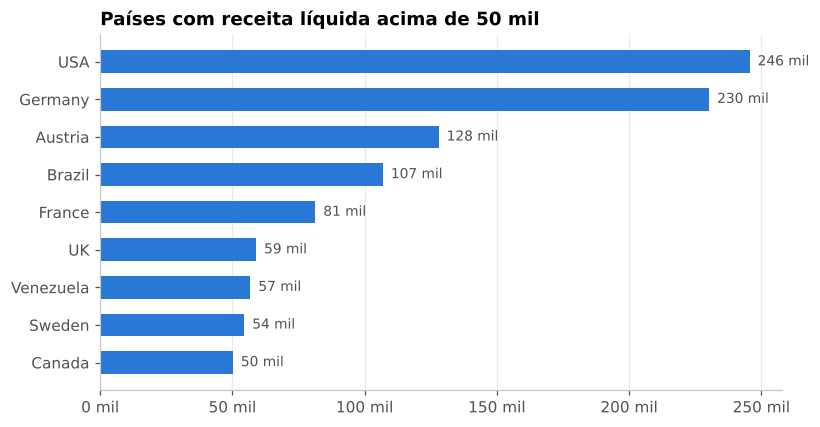

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = q13.sort_values("receita_liquida")
ax.barh(d["pais"], d["receita_liquida"], color=AZUL, height=0.6)
for y, v in enumerate(d["receita_liquida"]):
    ax.text(v + 3000, y, f"{v/1000:,.0f} mil".replace(",", "."), va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(milhar)
ax.grid(axis="y", visible=False)
ax.set_title("Países com receita líquida acima de 50 mil")
salvar(fig, "05_receita_por_pais.png")

In [17]:
q14 = rodar("Q14"); q14

[Q14] Desempenho por vendedor  (03_agregacoes.sql, 9 linhas)


,employee_id,vendedor,cargo,qtd_pedidos,receita_liquida,ticket_medio,desconto_medio_pct
0,4,Margaret Peacock,Sales Representative,156,232890.85,1492.89,6.1
1,3,Janet Leverling,Sales Representative,127,202812.84,1596.95,5.0
2,1,Nancy Davolio,Sales Representative,123,192107.60,1561.85,4.9
3,2,Andrew Fuller,"Vice President, Sales",96,166537.76,1734.77,4.4
4,8,Laura Callahan,Inside Sales Coordinator,104,126862.28,1219.83,5.6
5,7,Robert King,Sales Representative,72,124568.24,1730.11,7.4
6,9,Anne Dodsworth,Sales Representative,43,77308.07,1797.86,6.8
7,6,Michael Suyama,Sales Representative,67,73913.13,1103.18,5.4
8,5,Steven Buchanan,Sales Manager,42,68792.28,1637.91,6.7


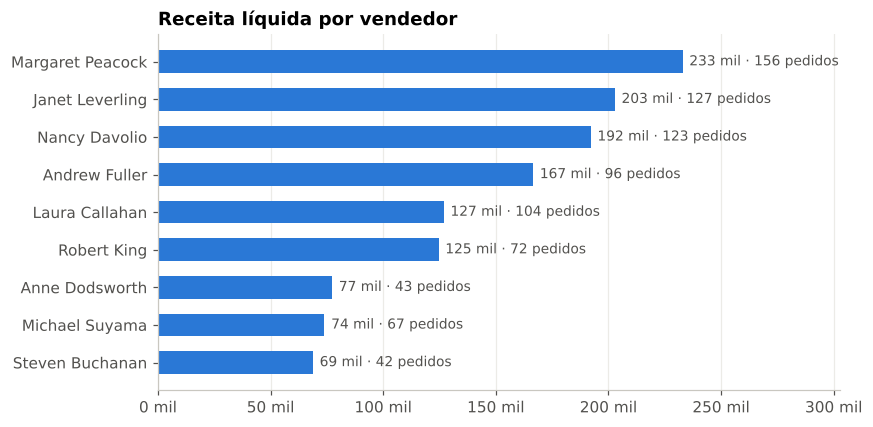

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = q14.sort_values("receita_liquida")
ax.barh(d["vendedor"], d["receita_liquida"], color=AZUL, height=0.6)
for y, (v, n) in enumerate(zip(d["receita_liquida"], d["qtd_pedidos"])):
    ax.text(v + 3000, y, f"{v/1000:,.0f} mil · {n} pedidos".replace(",", "."), va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(milhar)
ax.set_xlim(0, d["receita_liquida"].max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_title("Receita líquida por vendedor")
salvar(fig, "04_receita_por_vendedor.png")

In [19]:
q15 = rodar("Q15"); q15

[Q15] Receita líquida e pedidos por mês  (03_agregacoes.sql, 23 linhas)


,ano_mes,qtd_pedidos,receita_liquida
0,1996-07,22,27861.90
1,1996-08,25,25485.28
2,1996-09,23,26381.40
3,1996-10,26,37515.72
4,1996-11,25,45600.04
5,1996-12,31,45239.63
6,1997-01,33,61258.07
7,1997-02,29,38483.64
8,1997-03,30,38547.22
9,1997-04,31,53032.95


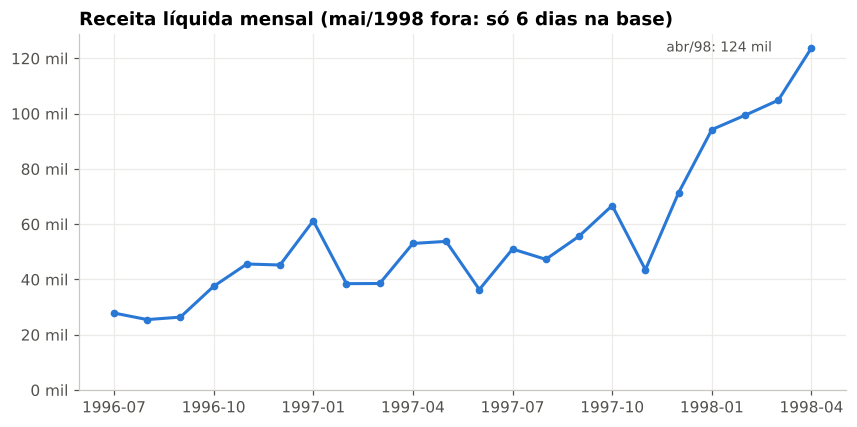

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.2))
cheio = q15[q15["ano_mes"] != "1998-05"]
ax.plot(cheio["ano_mes"], cheio["receita_liquida"], color=AZUL, linewidth=2, marker="o", markersize=4)
ax.yaxis.set_major_formatter(milhar)
ax.set_xticks(range(0, len(cheio), 3))
ax.set_xticklabels(cheio["ano_mes"].iloc[::3])
ult = cheio.iloc[-1]
ax.annotate(f"abr/98: {ult.receita_liquida/1000:,.0f} mil".replace(",", "."),
            (len(cheio) - 1, ult.receita_liquida), xytext=(-95, 0), textcoords="offset points",
            va="center", color="#52514e", fontsize=9)
ax.set_ylim(0, None)
ax.set_title("Receita líquida mensal (mai/1998 fora: só 6 dias na base)")
salvar(fig, "01_receita_mensal.png")

In [21]:
rodar("Q16")

[Q16] Top 10 clientes por receita líquida  (03_agregacoes.sql, 10 linhas)


,customer_id,cliente,pais,qtd_pedidos,receita_liquida,primeira_compra,ultima_compra
0,QUICK,QUICK-Stop,Germany,28,110277.30,1996-08-05,1998-04-14
1,ERNSH,Ernst Handel,Austria,30,104874.98,1996-07-17,1998-05-05
2,SAVEA,Save-a-lot Markets,USA,31,104361.95,1996-10-08,1998-05-01
3,RATTC,Rattlesnake Canyon Grocery,USA,18,51097.80,1996-07-22,1998-05-06
4,HUNGO,Hungry Owl All-Night Grocers,Ireland,19,49979.90,1996-09-05,1998-04-30
5,HANAR,Hanari Carnes,Brazil,14,32841.37,1996-07-08,1998-04-27
6,KOEN,Königlich Essen,Germany,14,30908.38,1996-10-07,1998-04-16
7,FOLKO,Folk och fä HB,Sweden,19,29567.56,1996-07-24,1998-04-27
8,MEREP,Mère Paillarde,Canada,13,28872.19,1996-10-17,1997-10-30
9,WHITC,White Clover Markets,USA,14,27363.60,1996-07-31,1998-05-01


In [22]:
rodar("Q17")

[Q17] Logística por transportadora: frete e prazo  (03_agregacoes.sql, 3 linhas)


,transportadora,pedidos_enviados,frete_total,frete_medio,prazo_medio_dias,pedidos_atrasados,atraso_pct
0,United Package,315,27556.76,87.48,9.2,16,5.1
1,Federal Shipping,249,20363.10,81.78,7.5,9,3.6
2,Speedy Express,245,16035.16,65.45,8.6,12,4.9


## Módulo 4 — Consultas para geração de indicadores (`sql/04_indicadores.sql`)

In [23]:
rodar("Q18").T.rename(columns={0: "valor"})

[Q18] Painel executivo — principais indicadores comerciais (1 linha)  (04_indicadores.sql, 1 linhas)


,valor
inicio_periodo,1996-07-04
fim_periodo,1998-05-06
qtd_pedidos,830
clientes_ativos,89
receita_bruta,1354458.59
descontos_concedidos,88665.55
desconto_pct_receita,6.5
receita_liquida,1265793.04
ticket_medio,1525.05
produtos_por_pedido,2.6


In [24]:
rodar("Q19").T.rename(columns={0: "valor"})

[Q19] Nível de serviço logístico (1 linha)  (04_indicadores.sql, 1 linhas)


,valor
total_pedidos,830.0
pedidos_enviados,809.0
pedidos_pendentes,21.0
no_prazo_pct,95.4
pedidos_atrasados,37.0
atraso_medio_dias_quando_atrasa,6.4
prazo_medio_envio_dias,8.5


In [25]:
q20 = rodar("Q20"); q20

[Q20] Comparativo justo de crescimento: jan–abr/1997 x jan–abr/1998  (04_indicadores.sql, 2 linhas)


,ano,pedidos,clientes_ativos,receita_liquida,ticket_medio,var_pedidos_pct,var_clientes_pct,var_receita_pct,var_ticket_pct
0,1997,123,65,191321.88,1555.46,NaN,NaN,NaN,NaN
1,1998,256,80,422290.24,1649.57,108.1,23.1,120.7,6.1


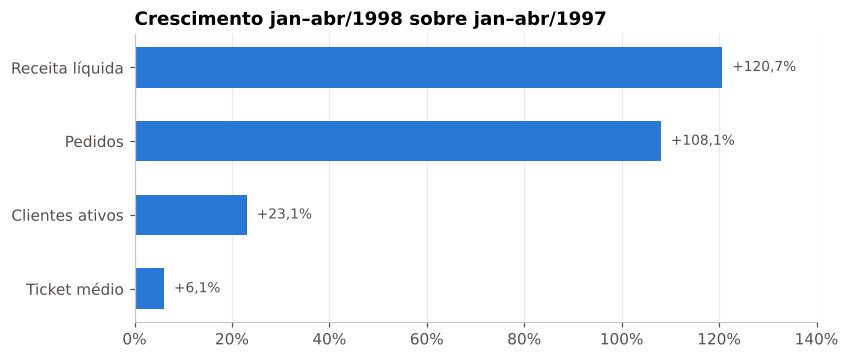

In [26]:
var = q20.iloc[-1][["var_receita_pct", "var_pedidos_pct", "var_clientes_pct", "var_ticket_pct"]]
rotulos = ["Receita líquida", "Pedidos", "Clientes ativos", "Ticket médio"]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(rotulos[::-1], var.values[::-1].astype(float), color=AZUL, height=0.55)
for y, v in enumerate(var.values[::-1]):
    ax.text(float(v) + 2, y, f"+{float(v):.1f}%".replace(".", ","), va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 140)
ax.grid(axis="y", visible=False)
ax.set_title("Crescimento jan–abr/1998 sobre jan–abr/1997")
salvar(fig, "06_crescimento_jan_abr.png")

In [27]:
rodar("Q21")

[Q21] Variação mês contra mês anterior (MoM) com LAG  (04_indicadores.sql, 22 linhas)


,ano_mes,receita_liquida,receita_mes_anterior,variacao_mom_pct
0,1996-07,27861.90,NaN,NaN
1,1996-08,25485.28,27861.90,-8.5
2,1996-09,26381.40,25485.28,3.5
3,1996-10,37515.72,26381.40,42.2
4,1996-11,45600.04,37515.72,21.5
5,1996-12,45239.63,45600.04,-0.8
6,1997-01,61258.07,45239.63,35.4
7,1997-02,38483.64,61258.07,-37.2
8,1997-03,38547.22,38483.64,0.2
9,1997-04,53032.95,38547.22,37.6


In [28]:
q22 = rodar("Q22"); q22.head(15)

[Q22] Curva ABC de produtos (classificação de Pareto)  (04_indicadores.sql, 77 linhas)


,posicao,product_id,product_name,receita_liquida,participacao_pct,acumulado_pct,classe_abc
0,1,38,Côte de Blaye,141396.73,11.17,11.17,A
1,2,29,Thüringer Rostbratwurst,80368.67,6.35,17.52,A
2,3,59,Raclette Courdavault,71155.70,5.62,23.14,A
3,4,62,Tarte au sucre,47234.97,3.73,26.87,A
4,5,60,Camembert Pierrot,46825.48,3.70,30.57,A
5,6,56,Gnocchi di nonna Alice,42593.06,3.36,33.94,A
6,7,51,Manjimup Dried Apples,41819.65,3.30,37.24,A
7,8,17,Alice Mutton,32698.38,2.58,39.82,A
8,9,18,Carnarvon Tigers,29171.88,2.30,42.13,A
9,10,28,Rössle Sauerkraut,25696.64,2.03,44.16,A


In [29]:
q22.groupby("classe_abc").agg(produtos=("product_id", "count"), receita_pct=("participacao_pct", "sum")).round(1)

,produtos,receita_pct
classe_abc,,
A,36,80.2
B,23,15.0
C,18,4.8


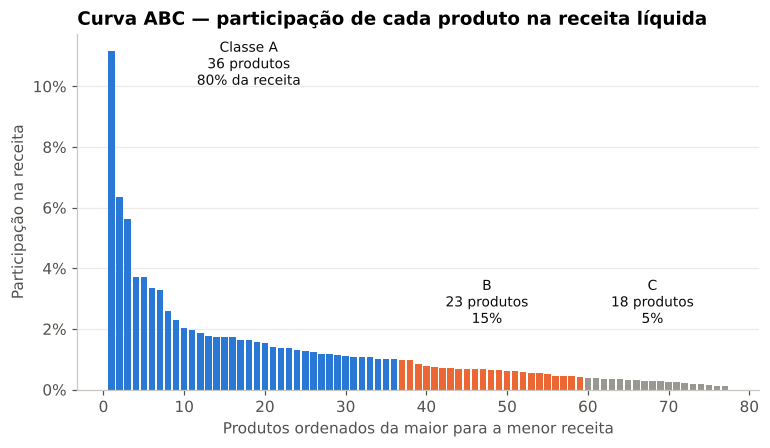

In [30]:
fig, ax = plt.subplots(figsize=(8, 4.2))
cores = q22["classe_abc"].map({"A": AZUL, "B": LARANJA, "C": CINZA})
ax.bar(q22["posicao"], q22["participacao_pct"], color=cores, width=0.8)
nA = (q22["classe_abc"] == "A").sum(); nB = (q22["classe_abc"] == "B").sum()
ax.text(nA / 2, q22["participacao_pct"].max() * 0.9, f"Classe A\n{nA} produtos\n80% da receita", ha="center", color="#0b0b0b", fontsize=9)
ax.text(nA + nB / 2, 2.2, f"B\n{nB} produtos\n15%", ha="center", color="#0b0b0b", fontsize=9)
ax.text(nA + nB + (77 - nA - nB) / 2, 2.2, f"C\n{77 - nA - nB} produtos\n5%", ha="center", color="#0b0b0b", fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Produtos ordenados da maior para a menor receita")
ax.set_ylabel("Participação na receita")
ax.grid(axis="x", visible=False)
ax.set_title("Curva ABC — participação de cada produto na receita líquida")
salvar(fig, "03_curva_abc_produtos.png")

## Módulo 5 — Perguntas de negócio (`sql/05_perguntas_negocio.sql`)

In [31]:
q23 = rodar("Q23"); q23.T.rename(columns={0: "valor"})

[Q23] Pergunta: "Quanto a empresa depende dos maiores clientes?"  (05_perguntas_negocio.sql, 1 linhas)


,valor
clientes_com_compra,89.0
top1_pct_receita,8.7
top5_pct_receita,33.2
top10_pct_receita,45.0
top20pct_clientes_pct_receita,60.1


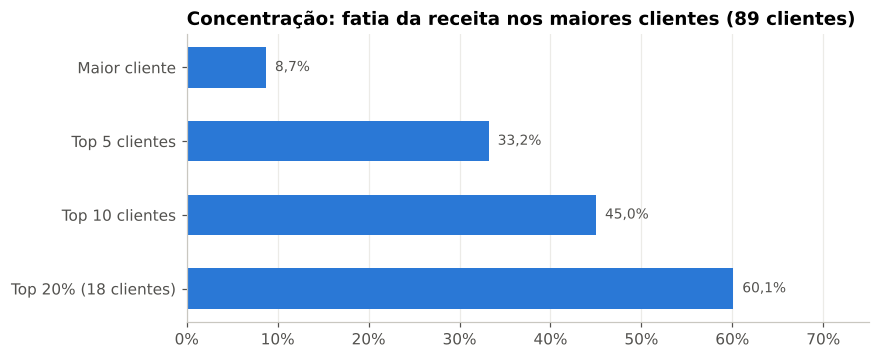

In [32]:
fig, ax = plt.subplots(figsize=(8, 3.4))
rot = ["Maior cliente", "Top 5 clientes", "Top 10 clientes", "Top 20% (18 clientes)"]
val = q23.iloc[0][["top1_pct_receita", "top5_pct_receita", "top10_pct_receita", "top20pct_clientes_pct_receita"]].astype(float).values
ax.barh(rot[::-1], val[::-1], color=AZUL, height=0.55)
for y, v in enumerate(val[::-1]):
    ax.text(v + 1, y, f"{v:.1f}%".replace(".", ","), va="center", color="#52514e", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 75)
ax.grid(axis="y", visible=False)
ax.set_title("Concentração: fatia da receita nos maiores clientes (89 clientes)")
salvar(fig, "07_concentracao_clientes.png")

In [33]:
rodar("Q24")

[Q24] Pergunta: "Quais clientes importantes pararam de comprar?"  (05_perguntas_negocio.sql, 16 linhas)


,customer_id,cliente,pais,qtd_pedidos,receita_historica,ultima_compra,dias_sem_comprar
0,MEREP,Mère Paillarde,Canada,13,28872.19,1997-10-30,188
1,BLONP,Blondesddsl père et fils,France,11,18534.08,1998-01-12,114
2,SEVES,Seven Seas Imports,UK,9,16215.32,1998-02-04,91
3,FOLIG,Folies gourmandes,France,5,11666.90,1997-12-22,135
4,VICT,Victuailles en stock,France,10,9182.43,1998-01-23,103
5,ANTON,Antonio Moreno Taquería,Mexico,7,7023.98,1998-01-28,98
6,TRADH,Tradição Hipermercados,Brazil,6,6850.66,1998-01-19,107
7,FAMIA,Familia Arquibaldo,Brazil,7,4107.55,1997-10-31,187
8,HUNGC,Hungry Coyote Import Store,USA,5,3063.20,1997-09-08,240
9,CONSH,Consolidated Holdings,UK,3,1719.10,1998-01-23,103


In [34]:
rodar("Q25")

[Q25] Pergunta: "Dar desconto está aumentando o tamanho do pedido?"  (05_perguntas_negocio.sql, 2 linhas)


,tipo_pedido,qtd_pedidos,unidades_medias_por_pedido,ticket_medio_liquido,valor_total_descontado
0,Com desconto,380,72.9,1702.35,88665.55
1,Sem desconto,450,52.4,1375.33,0.00


In [35]:
rodar("Q26")

[Q26] Pergunta: "Quais são os 3 produtos campeões de cada categoria?"  (05_perguntas_negocio.sql, 24 linhas)


,categoria,posicao,produto,receita_liquida,descontinuado
0,Beverages,1,Côte de Blaye,141396.73,Não
1,Beverages,2,Ipoh Coffee,23526.70,Não
2,Beverages,3,Chang,16355.96,Sim
3,Condiments,1,Vegie-spread,16701.10,Não
4,Condiments,2,Sirop d'érable,14352.60,Não
5,Condiments,3,Louisiana Fiery Hot Pepper Sauce,13869.89,Não
6,Confections,1,Tarte au sucre,47234.97,Não
7,Confections,2,Sir Rodney's Marmalade,22563.36,Não
8,Confections,3,Gumbär Gummibärchen,19849.14,Não
9,Dairy Products,1,Raclette Courdavault,71155.70,Não


In [36]:
rodar("Q27")

[Q27] Pergunta: "Estamos dependentes de poucos fornecedores?"  (05_perguntas_negocio.sql, 10 linhas)


,fornecedor,pais,produtos_vendidos,receita_liquida,participacao_pct
0,Aux joyeux ecclésiastiques,France,2,153691.27,12.1
1,Plutzer Lebensmittelgroßmärkte AG,Germany,5,145372.40,11.5
2,Gai pâturage,France,2,117981.18,9.3
3,"Pavlova, Ltd.",Australia,5,106459.78,8.4
4,"G'day, Mate",Australia,3,65626.77,5.2
5,Forêts d'érables,Canada,2,61587.57,4.9
6,"Specialty Biscuits, Ltd.",UK,5,59032.08,4.7
7,Pasta Buttini s.r.l.,Italy,2,50254.61,4.0
8,Formaggi Fortini s.r.l.,Italy,3,48225.17,3.8
9,Norske Meierier,Norway,3,43141.51,3.4


In [37]:
rodar("Q28")

[Q28] Pergunta: "Quanto da receita vem de produtos que já foram descontinuados?"  (05_perguntas_negocio.sql, 9 linhas)


,categoria,receita_liquida,receita_descontinuados,descontinuados_pct
0,Meat/Poultry,163022.36,140867.72,86.4
1,Produce,99984.58,25696.64,25.7
2,Beverages,267868.18,33648.43,12.6
3,Grains/Cereals,95744.59,8575.00,9.0
4,Condiments,106047.09,5347.20,5.0
5,Confections,167357.23,0.00,0.0
6,Dairy Products,234507.29,0.00,0.0
7,Seafood,131261.74,0.00,0.0
8,Total,1265793.04,214134.99,16.9


## O que a base responde — e o que não responde

| Responde | Não responde (precisaria de outra fonte) |
|---|---|
| Quanto, o quê, para quem e quando se vendeu | **Margem e lucro** — não há custo do produto |
| Quem vende mais e com quanto desconto | **Por que** um cliente parou de comprar (não há pesquisa, NPS, reclamações) |
| Pontualidade de envio por transportadora | **Data de entrega** ao cliente — só há data de envio |
| Concentração em clientes, produtos e fornecedores | **Efeito causal do desconto** — exigiria teste A/B |
| Estoque atual x ponto de reposição | **Histórico de estoque** — há só a foto atual, sem datas |
| Crescimento em períodos comparáveis (jan–abr) | **Metas** de vendas para comparar realizado x meta |

In [38]:
con.close()